# Phase 10: Comparative Analysis of Traditional Restoration Methods Under Combined MRI Degradation

## Academic Project Context
**Project Title:** *Comparative Analysis of Brain MRI Image Restoration Techniques Under Different Degradation Conditions*

### Objective
In this phase, we conduct rigorous comparative evaluation of four traditional image restoration filters on MRI scans subject to simultaneous multi-degradation:
$$\mathbf{I}_{\text{clean}} \xrightarrow{\text{Low-Res}} \mathbf{I}_{\text{LR}} \xrightarrow{\text{Motion Blur}} \mathbf{I}_{\text{LR+Blur}} \xrightarrow{\text{Rician Noise}} \mathbf{I}_{\text{combined}}$$

### Restoration Methods Evaluated:
1. **Median Filter (3x3):** Non-linear spatial rank filter targeting impulse and non-Gaussian noise.
2. **Non-Local Means (NLM):** Non-local patch redundancy filter exploiting anatomical structural symmetry.
3. **Adaptive Wiener Filter (5x5):** Local minimum mean-squared error (MMSE) filter based on local spatial statistics.
4. **Lanczos Sharpening:** High-frequency spatial unsharp masking to counteract downsampling and motion blur.

### Evaluation Protocol & Scale:
- **Training Combined Restoration:** 39,200 degraded scans $\times$ 4 filters = **156,800 evaluation records**
- **Testing Combined Restoration:** 11,200 degraded scans $\times$ 4 filters = **44,800 evaluation records**
- **Total Quantitative Records:** **201,600 evaluations** evaluated against corresponding clean original scans using MSE, PSNR, and SSIM.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r'C:\Users\gitan\BrainMRI_Project')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.restoration import RESTORATION_METHODS

METRICS_DIR = PROJECT_ROOT / 'outputs' / 'metrics'
TRAIN_METRICS_CSV = METRICS_DIR / 'phase10_combined_training_metrics.csv'
TRAIN_SUMMARY_CSV = METRICS_DIR / 'phase10_combined_training_summary.csv'
TEST_METRICS_CSV  = METRICS_DIR / 'phase10_combined_testing_metrics.csv'
TEST_SUMMARY_CSV  = METRICS_DIR / 'phase10_combined_testing_summary.csv'

CATEGORIES = ['glioma', 'meningioma', 'notumor', 'pituitary']
SEVERITY_LEVELS = [10, 20, 30, 40, 50, 60, 70]
METHODS = ['median_filter', 'nlm', 'wiener', 'lanczos_sharpening']

print('=== Phase 10: Environment and Paths Initialized ===')
print(f'Training Metrics CSV: {TRAIN_METRICS_CSV}')
print(f'Testing Metrics CSV:  {TEST_METRICS_CSV}')


=== Phase 10: Environment and Paths Initialized ===
Training Metrics CSV: C:\Users\gitan\BrainMRI_Project\outputs\metrics\phase10_combined_training_metrics.csv
Testing Metrics CSV:  C:\Users\gitan\BrainMRI_Project\outputs\metrics\phase10_combined_testing_metrics.csv


In [2]:
df_train = pd.read_csv(TRAIN_METRICS_CSV)
df_test  = pd.read_csv(TEST_METRICS_CSV)

print(f'Training Combined Evaluations: {len(df_train):,} / 156,800 expected (Match: {len(df_train) == 156800})')
print(f'Testing Combined Evaluations:  {len(df_test):,} / 44,800 expected (Match: {len(df_test) == 44800})')
print(f'Total Combined Quantitative Records: {len(df_train) + len(df_test):,} / 201,600 expected')

# Verify 0 missing values or errors
train_nulls = df_train[['MSE', 'PSNR', 'SSIM']].isna().sum().sum()
test_nulls  = df_test[['MSE', 'PSNR', 'SSIM']].isna().sum().sum()
print(f'Training NaN/Null Count: {train_nulls}')
print(f'Testing NaN/Null Count:  {test_nulls}')


Training Combined Evaluations: 156,800 / 156,800 expected (Match: True)
Testing Combined Evaluations:  44,800 / 44,800 expected (Match: True)
Total Combined Quantitative Records: 201,600 / 201,600 expected
Training NaN/Null Count: 0
Testing NaN/Null Count:  0


In [3]:
df_train_sum = pd.read_csv(TRAIN_SUMMARY_CSV)
df_test_sum  = pd.read_csv(TEST_SUMMARY_CSV)

table_train = df_train_sum.groupby('restoration_method').agg({
    'mean_psnr': 'mean',
    'mean_ssim': 'mean',
    'mean_mse':  'mean'
}).reset_index()
table_train.columns = ['Restoration Method', 'Train Mean PSNR (dB)', 'Train Mean SSIM', 'Train Mean MSE']

table_test = df_test_sum.groupby('restoration_method').agg({
    'mean_psnr': 'mean',
    'mean_ssim': 'mean',
    'mean_mse':  'mean'
}).reset_index()
table_test.columns = ['Restoration Method', 'Test Mean PSNR (dB)', 'Test Mean SSIM', 'Test Mean MSE']

overall = pd.merge(table_train, table_test, on='Restoration Method')
print('=== Phase 10: Overall Restoration Performance on Combined Multi-Degradation ===')
print(overall.to_string(index=False))


=== Phase 10: Overall Restoration Performance on Combined Multi-Degradation ===
Restoration Method  Train Mean PSNR (dB)  Train Mean SSIM  Train Mean MSE  Test Mean PSNR (dB)  Test Mean SSIM  Test Mean MSE
lanczos_sharpening              6.867656         0.020337        0.259063             6.911806        0.020950       0.255669
     median_filter             10.012609         0.116403        0.191475            10.126952        0.120824       0.187383
               nlm              8.741242         0.051437        0.214845             8.816118        0.052781       0.210830
            wiener             10.284716         0.173249        0.165265            10.418022        0.180762       0.161209


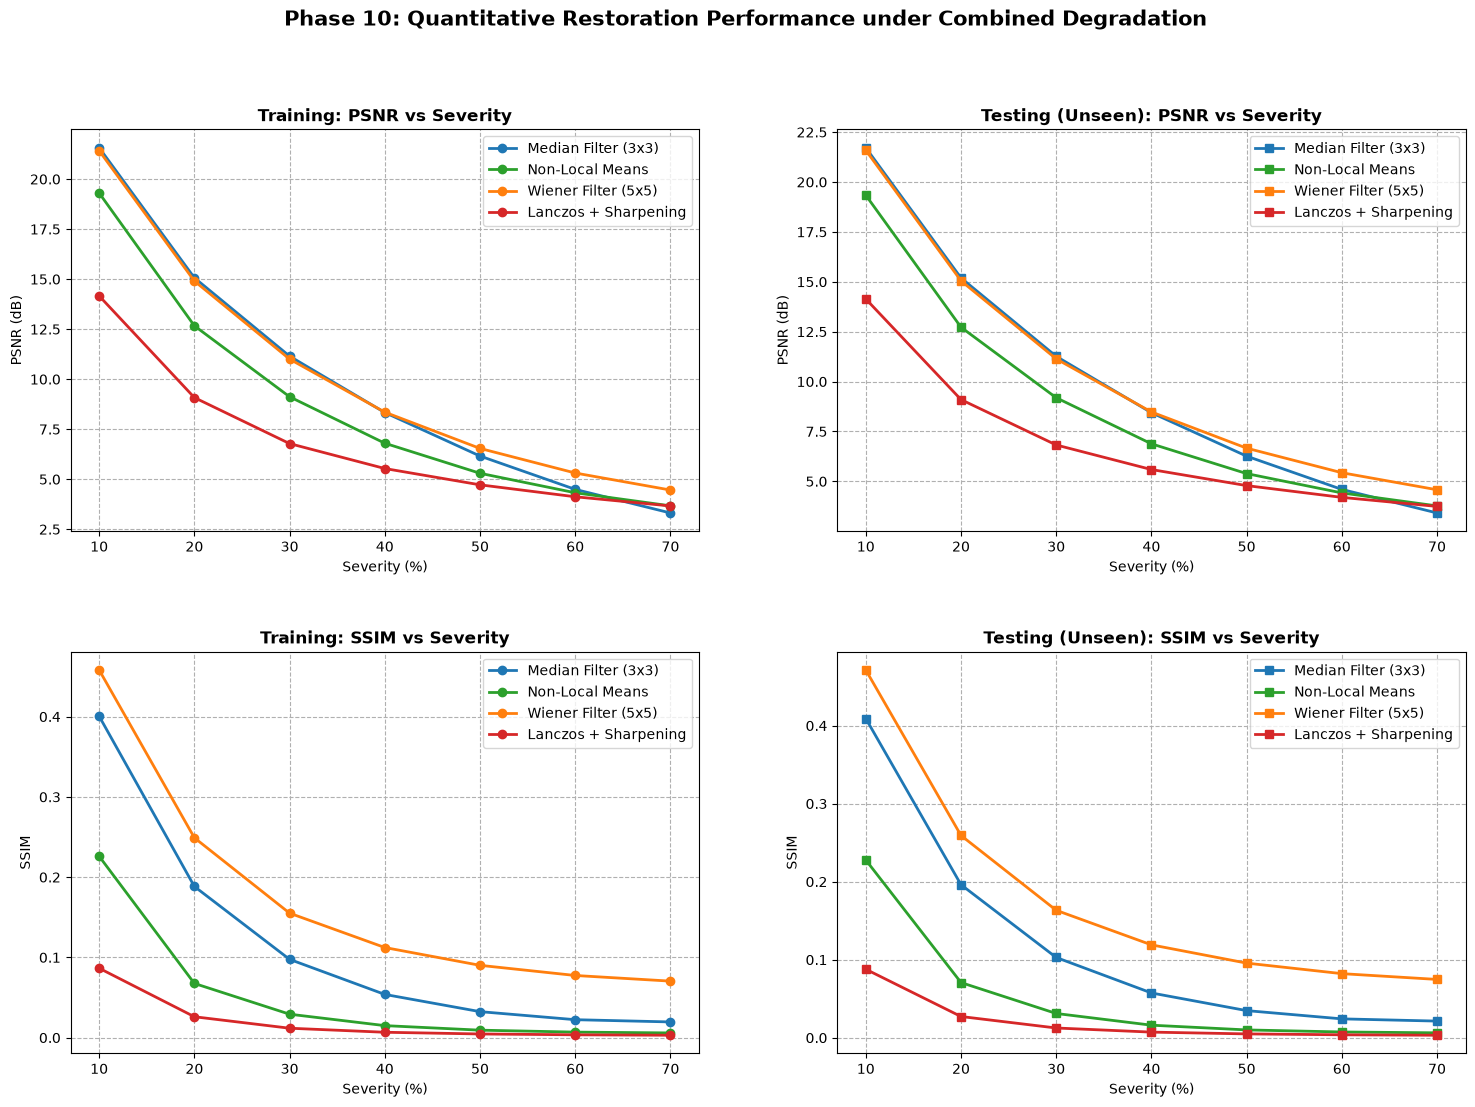

In [4]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
plt.subplots_adjust(wspace=0.22, hspace=0.30)

colors = {'median_filter': '#1f77b4', 'nlm': '#2ca02c', 'wiener': '#ff7f0e', 'lanczos_sharpening': '#d62728'}
labels = {'median_filter': 'Median Filter (3x3)', 'nlm': 'Non-Local Means', 'wiener': 'Wiener Filter (5x5)', 'lanczos_sharpening': 'Lanczos + Sharpening'}

# 1. PSNR Train
for m in METHODS:
    s = df_train_sum[df_train_sum['restoration_method'] == m].groupby('severity')['mean_psnr'].mean()
    axes[0, 0].plot(s.index, s.values, marker='o', linewidth=2, label=labels[m], color=colors[m])
axes[0, 0].set_title('Training: PSNR vs Severity', fontweight='bold')
axes[0, 0].set_xlabel('Severity (%)'); axes[0, 0].set_ylabel('PSNR (dB)'); axes[0, 0].grid(True, linestyle='--'); axes[0, 0].legend()

# 2. PSNR Test
for m in METHODS:
    s = df_test_sum[df_test_sum['restoration_method'] == m].groupby('severity')['mean_psnr'].mean()
    axes[0, 1].plot(s.index, s.values, marker='s', linewidth=2, label=labels[m], color=colors[m])
axes[0, 1].set_title('Testing (Unseen): PSNR vs Severity', fontweight='bold')
axes[0, 1].set_xlabel('Severity (%)'); axes[0, 1].set_ylabel('PSNR (dB)'); axes[0, 1].grid(True, linestyle='--'); axes[0, 1].legend()

# 3. SSIM Train
for m in METHODS:
    s = df_train_sum[df_train_sum['restoration_method'] == m].groupby('severity')['mean_ssim'].mean()
    axes[1, 0].plot(s.index, s.values, marker='o', linewidth=2, label=labels[m], color=colors[m])
axes[1, 0].set_title('Training: SSIM vs Severity', fontweight='bold')
axes[1, 0].set_xlabel('Severity (%)'); axes[1, 0].set_ylabel('SSIM'); axes[1, 0].grid(True, linestyle='--'); axes[1, 0].legend()

# 4. SSIM Test
for m in METHODS:
    s = df_test_sum[df_test_sum['restoration_method'] == m].groupby('severity')['mean_ssim'].mean()
    axes[1, 1].plot(s.index, s.values, marker='s', linewidth=2, label=labels[m], color=colors[m])
axes[1, 1].set_title('Testing (Unseen): SSIM vs Severity', fontweight='bold')
axes[1, 1].set_xlabel('Severity (%)'); axes[1, 1].set_ylabel('SSIM'); axes[1, 1].grid(True, linestyle='--'); axes[1, 1].legend()

fig.suptitle('Phase 10: Quantitative Restoration Performance under Combined Degradation', fontsize=15, fontweight='bold', y=0.98)
plt.show()


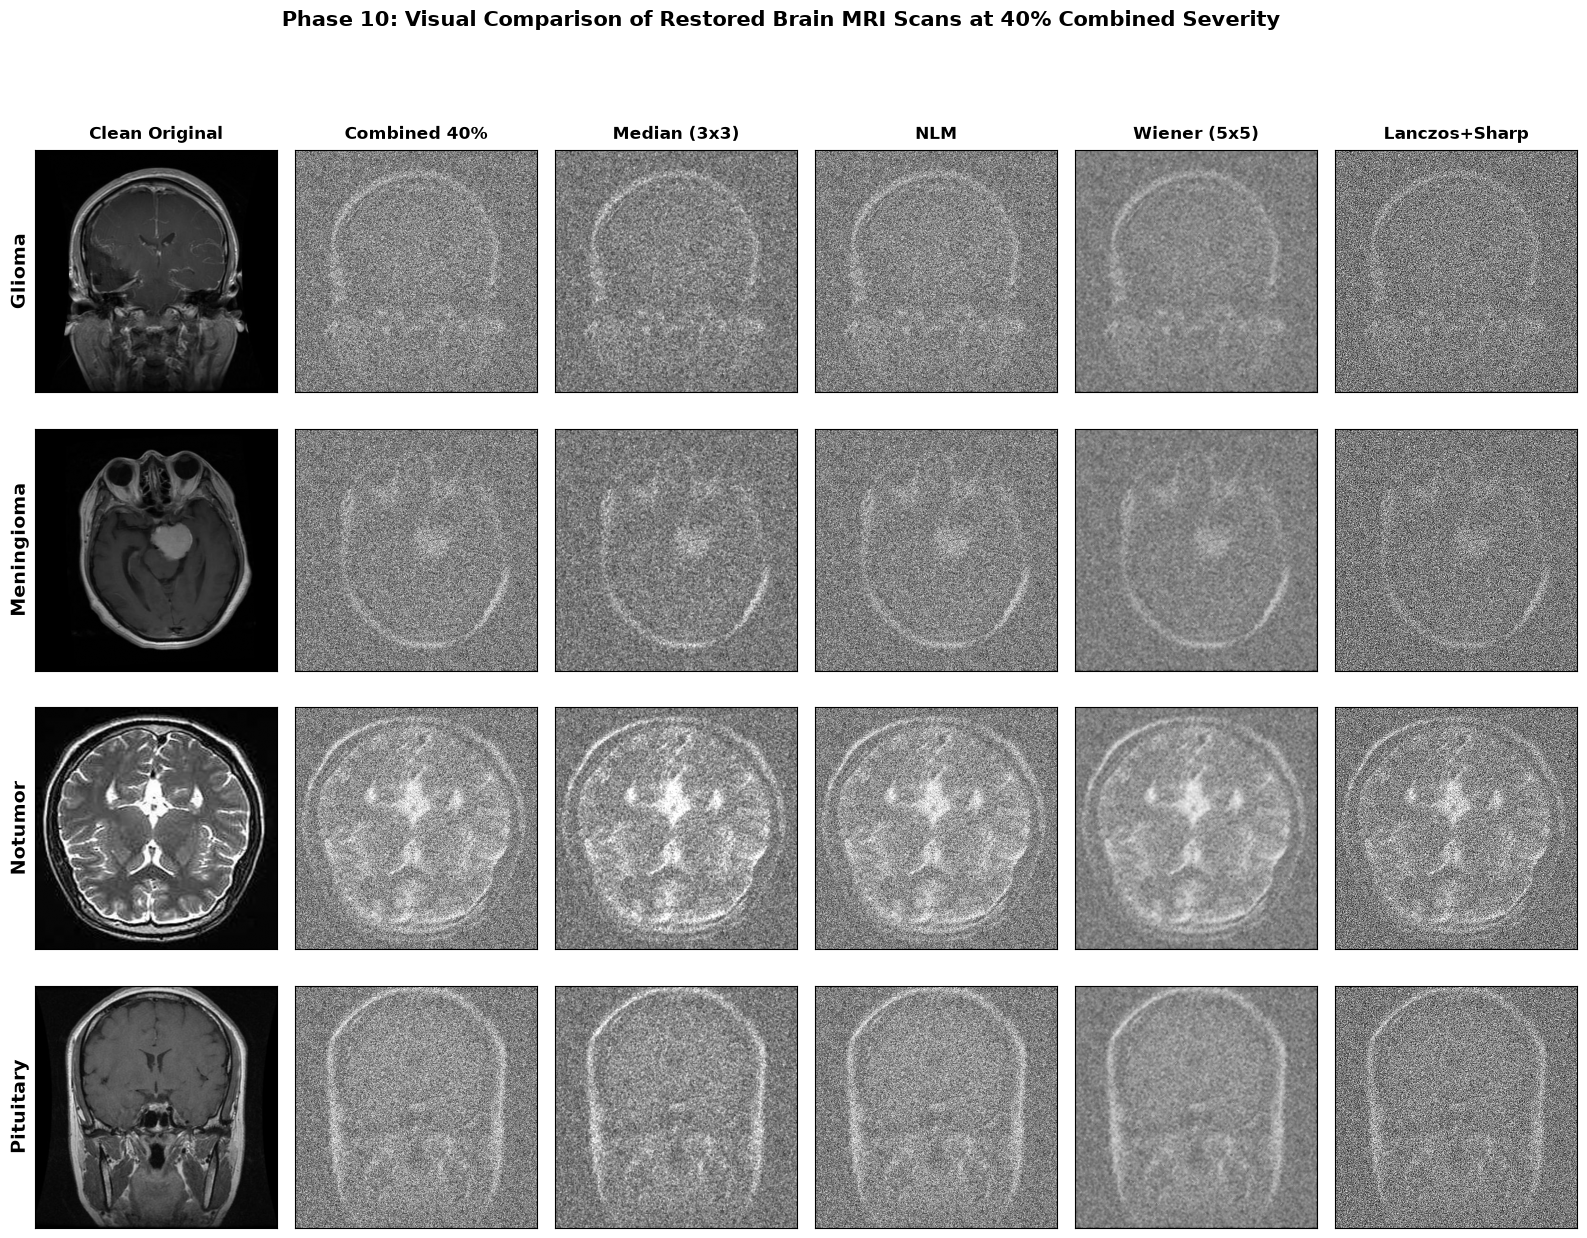

In [5]:
TRAIN_CLEAN_DIR  = PROJECT_ROOT / 'dataset' / 'archive' / 'Training'
TRAIN_DEG_DIR    = PROJECT_ROOT / 'dataset' / 'degraded' / 'combined'
TRAIN_SAMPLE_DIR = PROJECT_ROOT / 'outputs' / 'samples' / 'phase10_restored'

fig, axes = plt.subplots(nrows=4, ncols=6, figsize=(20, 14))
plt.subplots_adjust(wspace=0.04, hspace=0.15)
col_headers = ['Clean Original', 'Combined 40%', 'Median (3x3)', 'NLM', 'Wiener (5x5)', 'Lanczos+Sharp']

for row_idx, cat in enumerate(CATEGORIES):
    clean_files = sorted(list((TRAIN_CLEAN_DIR / cat).glob('*.*')))
    clean_p = clean_files[0]
    stem = clean_p.stem

    # Clean
    with Image.open(clean_p) as img:
        clean_arr = np.array(img.convert('L').resize((512, 512)))
    axes[row_idx, 0].imshow(clean_arr, cmap='gray', vmin=0, vmax=255)
    axes[row_idx, 0].set_ylabel(cat.capitalize(), fontsize=14, fontweight='bold')
    axes[row_idx, 0].set_xticks([]); axes[row_idx, 0].set_yticks([])
    if row_idx == 0: axes[row_idx, 0].set_title(col_headers[0], fontsize=12, fontweight='bold', pad=8)

    # Degraded 40%
    deg_p = TRAIN_DEG_DIR / cat / '40' / f'{stem}_combined_40.png'
    with Image.open(deg_p) as img: deg_arr = np.array(img)
    axes[row_idx, 1].imshow(deg_arr, cmap='gray', vmin=0, vmax=255)
    axes[row_idx, 1].set_xticks([]); axes[row_idx, 1].set_yticks([])
    if row_idx == 0: axes[row_idx, 1].set_title(col_headers[1], fontsize=12, fontweight='bold', pad=8)

    # 4 Restored Methods
    for col_idx, method in enumerate(METHODS, start=2):
        rest_p = TRAIN_SAMPLE_DIR / method / cat / '40' / f'{stem}_combined_40_restored_{method}.png'
        with Image.open(rest_p) as img: rest_arr = np.array(img)
        axes[row_idx, col_idx].imshow(rest_arr, cmap='gray', vmin=0, vmax=255)
        axes[row_idx, col_idx].set_xticks([]); axes[row_idx, col_idx].set_yticks([])
        if row_idx == 0: axes[row_idx, col_idx].set_title(col_headers[col_idx], fontsize=12, fontweight='bold', pad=8)

fig.suptitle('Phase 10: Visual Comparison of Restored Brain MRI Scans at 40% Combined Severity', fontsize=15, fontweight='bold', y=0.98)
plt.show()
